<a href="https://colab.research.google.com/github/davidfwallace/metastase-pcam/blob/main/notebooks/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Baseline: uma CNN treinada do zero

**Objetivo:** preparar os dados para o PyTorch, montar o ciclo de treino (com checkpoints e retomada) e treinar uma rede convolucional pequena, do zero. Ela é a régua para o transfer learning — e precisa superar a régua de cor e brilho do notebook 01 (ROC AUC de 0,810).

In [1]:
import subprocess
import sys
from pathlib import Path

import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA — ative a T4!")

# Código do projeto: clona o repositório (ou atualiza, se já estiver clonado)
REPO_DIR = Path("/content/metastase-pcam")
if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/davidfwallace/metastase-pcam.git", str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR))

from google.colab import drive
drive.mount("/content/drive")
RAIZ_DADOS = Path("/content/drive/MyDrive/metastase-pcam")
DATA_DIR = RAIZ_DADOS / "data"
CACHE_DIR = Path("/content/cache")  # disco local do Colab: rápido, mas apagado ao fim da sessão

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from src.dados import preparar_split

X_treino, y_treino = preparar_split(DATA_DIR, "train", CACHE_DIR)
X_valid, y_valid = preparar_split(DATA_DIR, "valid", CACHE_DIR)
print(f"Treino: {X_treino.shape}, {X_treino.dtype} | fração positiva {y_treino.mean():.3f}")
print(f"Validação: {X_valid.shape} | fração positiva {y_valid.mean():.3f}")

Treino: (262144, 96, 96, 3), uint8 | fração positiva 0.500
Validação: (32768, 96, 96, 3) | fração positiva 0.500


In [3]:
import time

import torch

from src.dataset import carregador, preparar_lote

TAMANHO_LOTE = 256
carregador_treino = carregador(X_treino, y_treino, TAMANHO_LOTE, embaralhar=True)
carregador_valid = carregador(X_valid, y_valid, TAMANHO_LOTE, embaralhar=False)

imagens, rotulos = next(iter(carregador_treino))
print("Lote cru:", tuple(imagens.shape), imagens.dtype, "| rótulos:", tuple(rotulos.shape), rotulos.dtype)
x = preparar_lote(imagens.cuda(), aumento=True)
print("Lote preparado:", tuple(x.shape), x.dtype, f"| valores entre {x.min():.2f} e {x.max():.2f}")
print(f"Lotes por época: treino {len(carregador_treino)}, validação {len(carregador_valid)}")

def medir_velocidade(n_lotes=100):
    """Imagens/s de leitura + preparo, sem contar a subida dos workers."""
    lotes = iter(carregador_treino)
    next(lotes)  # aquecimento: os workers sobem e entregam o primeiro lote
    torch.cuda.synchronize()
    inicio = time.time()
    for _ in range(n_lotes):
        imagens, rotulos = next(lotes)
        x = preparar_lote(imagens.cuda(non_blocking=True), aumento=True)
    torch.cuda.synchronize()  # a GPU trabalha em paralelo; espera ela terminar antes de parar o relógio
    return n_lotes * TAMANHO_LOTE / (time.time() - inicio)

velocidade = medir_velocidade()
print(f"Leitura + preparo: ~{velocidade:,.0f} imagens/s "
      f"(~{len(y_treino) / velocidade:.0f} s por época só nisso)")

Lote cru: (256, 96, 96, 3) torch.uint8 | rótulos: (256,) torch.float32
Lote preparado: (256, 3, 96, 96) torch.float32 | valores entre -2.12 e 2.64
Lotes por época: treino 1024, validação 128
Leitura + preparo: ~1,879 imagens/s (~139 s por época só nisso)


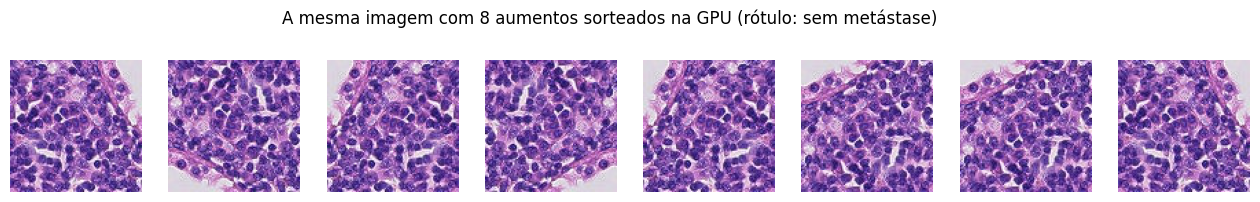

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from src.dataset import DESVIO, MEDIA

def para_exibir(tensor):
    """Desfaz a normalização para mostrar a imagem."""
    media = torch.tensor(MEDIA).view(3, 1, 1)
    desvio = torch.tensor(DESVIO).view(3, 1, 1)
    return (tensor.cpu() * desvio + media).clamp(0, 1).permute(1, 2, 0).numpy()

# A MESMA imagem repetida 8 vezes no lote: cada cópia sorteia a sua simetria
copias = torch.from_numpy(np.array(X_treino[0]))[None].repeat(8, 1, 1, 1).cuda()
aumentadas = preparar_lote(copias, aumento=True)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, imagem in zip(axes, aumentadas):
    ax.imshow(para_exibir(imagem))
    ax.axis("off")
fig.suptitle(f"A mesma imagem com 8 aumentos sorteados na GPU "
             f"(rótulo: {'com' if y_treino[0] else 'sem'} metástase)")
plt.show()

In [5]:
from torch import nn

from src.modelos import CNNPequena

torch.manual_seed(42)
modelo = CNNPequena().cuda()
n_parametros = sum(p.numel() for p in modelo.parameters())
print(f"Parâmetros: {n_parametros:,}")

# Um lote passando pela rede ainda não treinada
imagens, rotulos = next(iter(carregador_treino))
imagens, rotulos = imagens.cuda(), rotulos.cuda()
with torch.no_grad():
    logits = modelo(preparar_lote(imagens, aumento=False))
    perda = nn.BCEWithLogitsLoss()(logits, rotulos)

print("Saída:", tuple(logits.shape), "| primeiros logits:", logits[:5].cpu().numpy().round(3))
print(f"Probabilidade média: {torch.sigmoid(logits).mean():.3f}")
print(f"Perda inicial: {perda:.3f} (referência: chutar 50% para tudo dá ln 2 = 0.693)")

Parâmetros: 1,173,473
Saída: (256,) | primeiros logits: [0.151 1.062 0.561 0.422 0.671]
Probabilidade média: 0.515
Perda inicial: 0.711 (referência: chutar 50% para tudo dá ln 2 = 0.693)


In [8]:
from src.treino import avaliar, treinar_uma_epoca

torch.manual_seed(42)
modelo = CNNPequena().cuda()
otimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
escalador = torch.amp.GradScaler("cuda")

inicio = time.time()
perda_treino = treinar_uma_epoca(modelo, carregador_treino, otimizador, escalador)
tempo_treino = time.time() - inicio

inicio = time.time()
metricas = avaliar(modelo, carregador_valid)
tempo_valid = time.time() - inicio

print(f"Treino: perda {perda_treino:.3f} | {tempo_treino:.0f} s")
print(f"Validação: perda {metricas['perda']:.3f} | AUC {metricas['auc']:.3f} | "
      f"acurácia {metricas['acuracia']:.3f} | {tempo_valid:.0f} s")
print("Régua (cor e brilho, regressão logística): AUC 0.810")

Treino: perda 0.297 | 183 s
Validação: perda 0.444 | AUC 0.916 | acurácia 0.823 | 5 s
Régua (cor e brilho, regressão logística): AUC 0.810


In [6]:
from src.treino import treinar

RAIZ = DATA_DIR.parent  # MyDrive/metastase-pcam
CHECKPOINTS = RAIZ / "checkpoints" / "cnn_pequena"
print("Checkpoints em:", CHECKPOINTS)

torch.manual_seed(42)
modelo = CNNPequena().cuda()
historico = treinar(modelo, carregador_treino, carregador_valid,
                    n_epocas=15, pasta_checkpoints=CHECKPOINTS)

Checkpoints em: /content/drive/MyDrive/metastase-pcam/checkpoints/cnn_pequena
Época  1/15 | lr 1.00e-03 | treino 0.297 | valid perda 0.444 AUC 0.916 acurácia 0.823 | 189 s | recorde
Época  2/15 | lr 9.89e-04 | treino 0.185 | valid perda 0.317 AUC 0.953 acurácia 0.883 | 173 s | recorde
Época  3/15 | lr 9.57e-04 | treino 0.158 | valid perda 0.353 AUC 0.951 acurácia 0.863 | 175 s
Época  4/15 | lr 9.05e-04 | treino 0.143 | valid perda 0.328 AUC 0.943 acurácia 0.864 | 175 s
Época  5/15 | lr 8.35e-04 | treino 0.131 | valid perda 0.433 AUC 0.939 acurácia 0.844 | 172 s
Época  6/15 | lr 7.50e-04 | treino 0.121 | valid perda 0.313 AUC 0.956 acurácia 0.888 | 171 s | recorde
Época  7/15 | lr 6.55e-04 | treino 0.113 | valid perda 0.315 AUC 0.957 acurácia 0.881 | 175 s | recorde
Época  8/15 | lr 5.52e-04 | treino 0.106 | valid perda 0.433 AUC 0.947 acurácia 0.850 | 178 s
Época  9/15 | lr 4.48e-04 | treino 0.098 | valid perda 0.396 AUC 0.947 acurácia 0.871 | 175 s
Época 10/15 | lr 3.45e-04 | treino 0

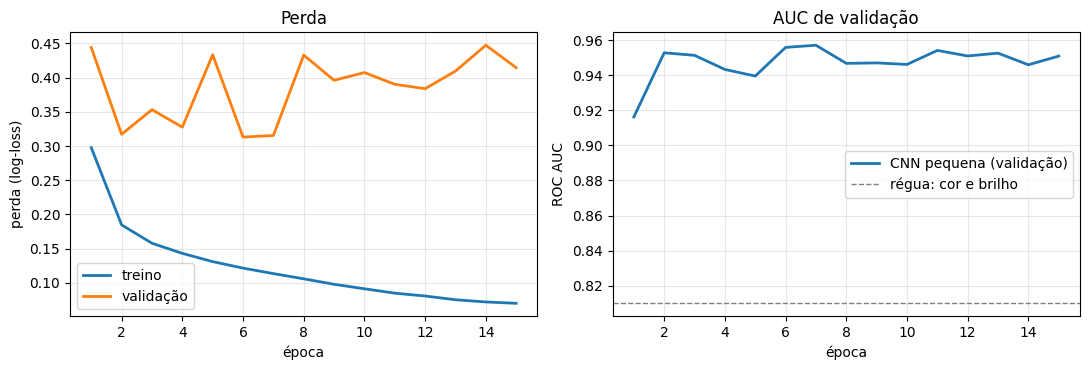

 epoca    lr  perda_treino  valid_perda  valid_auc  valid_acuracia  segundos
     1 0.001         0.297        0.444      0.916           0.823   188.895
     2 0.001         0.185        0.317      0.953           0.883   173.160
     3 0.001         0.158        0.353      0.951           0.863   175.189
     4 0.001         0.143        0.328      0.943           0.864   175.025
     5 0.001         0.131        0.433      0.939           0.844   171.514
     6 0.001         0.121        0.313      0.956           0.888   170.926
     7 0.001         0.113        0.315      0.957           0.881   175.247
     8 0.001         0.106        0.433      0.947           0.850   177.746
     9 0.000         0.098        0.396      0.947           0.871   175.447
    10 0.000         0.091        0.407      0.946           0.867   178.073
    11 0.000         0.085        0.390      0.954           0.872   179.045
    12 0.000         0.081        0.384      0.951           0.875   179.697

In [7]:
import pandas as pd

curvas = pd.DataFrame(historico)
REPORTS_DIR = RAIZ / "reports"
curvas.to_csv(REPORTS_DIR / "02_historico_cnn_pequena.csv", index=False)

fig, (ax_perda, ax_auc) = plt.subplots(1, 2, figsize=(11, 3.8))
ax_perda.plot(curvas["epoca"], curvas["perda_treino"], lw=2, label="treino")
ax_perda.plot(curvas["epoca"], curvas["valid_perda"], lw=2, label="validação")
ax_perda.set(xlabel="época", ylabel="perda (log-loss)", title="Perda")
ax_auc.plot(curvas["epoca"], curvas["valid_auc"], lw=2, label="CNN pequena (validação)")
ax_auc.axhline(0.810, color="gray", ls="--", lw=1, label="régua: cor e brilho")
ax_auc.set(xlabel="época", ylabel="ROC AUC", title="AUC de validação")
for ax in (ax_perda, ax_auc):
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(REPORTS_DIR / "figures" / "02_curvas_cnn_pequena.png", dpi=150, bbox_inches="tight")
plt.show()

print(curvas.round(3).to_string(index=False))

Melhor época: 7 (AUC de validação 0.957)
Sensibilidade (metástases encontradas): 0.794
Especificidade (tecido normal reconhecido): 0.968
Fração prevista como metástase: 0.413 (real: 0.500)


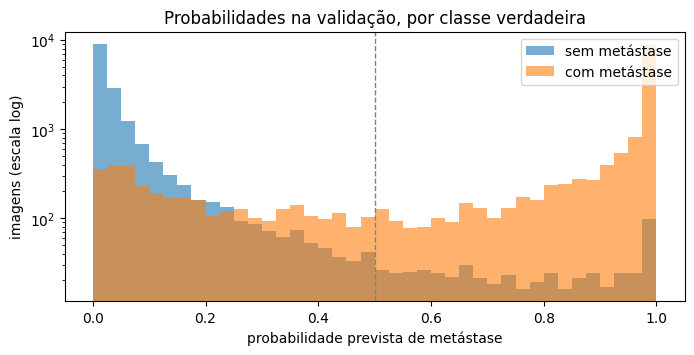

In [8]:
from sklearn.metrics import confusion_matrix

from src.treino import prever

melhor = torch.load(CHECKPOINTS / "melhor.pt", map_location="cuda", weights_only=True)
modelo.load_state_dict(melhor["modelo"])
print(f"Melhor época: {melhor['epoca']} (AUC de validação {melhor['valid_auc']:.3f})")

logits, y = prever(modelo, carregador_valid)
prob = torch.sigmoid(torch.from_numpy(logits)).numpy()
vn, fp, fn, vp = confusion_matrix(y, prob > 0.5).ravel()
print(f"Sensibilidade (metástases encontradas): {vp / (vp + fn):.3f}")
print(f"Especificidade (tecido normal reconhecido): {vn / (vn + fp):.3f}")
print(f"Fração prevista como metástase: {(prob > 0.5).mean():.3f} (real: {y.mean():.3f})")

fig, ax = plt.subplots(figsize=(8, 3.5))
faixas = np.linspace(0, 1, 41)
ax.hist(prob[y == 0], bins=faixas, alpha=0.6, label="sem metástase")
ax.hist(prob[y == 1], bins=faixas, alpha=0.6, label="com metástase")
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set(xlabel="probabilidade prevista de metástase", ylabel="imagens (escala log)",
       yscale="log", title="Probabilidades na validação, por classe verdadeira")
ax.legend()
fig.savefig(REPORTS_DIR / "figures" / "02_probabilidades_valid.png", dpi=150, bbox_inches="tight")
plt.show()

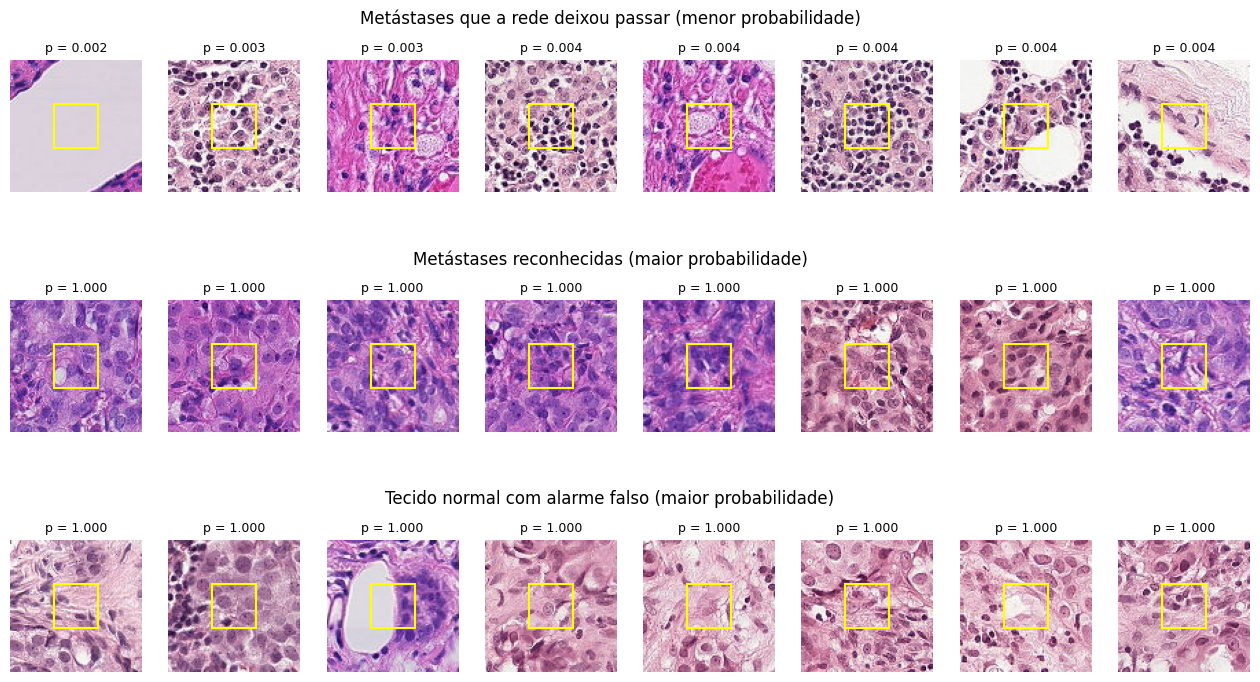

In [9]:
from matplotlib.patches import Rectangle

positivos = np.where(y == 1)[0]
negativos = np.where(y == 0)[0]
grupos = {
    "Metástases que a rede deixou passar (menor probabilidade)": positivos[np.argsort(prob[positivos])[:8]],
    "Metástases reconhecidas (maior probabilidade)": positivos[np.argsort(prob[positivos])[-8:]],
    "Tecido normal com alarme falso (maior probabilidade)": negativos[np.argsort(prob[negativos])[-8:]],
}

fig = plt.figure(figsize=(16, 7.2))
for subfig, (titulo, indices) in zip(fig.subfigures(3, 1), grupos.items()):
    subfig.suptitle(titulo, fontsize=12)
    for ax, i in zip(subfig.subplots(1, 8), indices):
        ax.imshow(X_valid[i])
        ax.add_patch(Rectangle((31.5, 31.5), 32, 32, fill=False, edgecolor="yellow", linewidth=1.5))
        ax.set_title(f"p = {prob[i]:.3f}", fontsize=9)
        ax.axis("off")
fig.savefig(REPORTS_DIR / "figures" / "02_erros_valid.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões

**Desempenho.** A CNN pequena (1,17 milhão de parâmetros, treinada do zero) chega a **AUC de validação ~0,95** já na época 2 e fica estável nesse patamar — muito acima da régua de cor e brilho (0,810). A rede aprendeu padrões de tecido, não só "tem fundo branco".

**Sobreajuste na calibração, não na ordenação.** A perda de treino cai sem parar (0,30 → 0,07), enquanto a de validação atinge o mínimo (~0,31) nas épocas 2 e 6 e depois sobe para ~0,40. A AUC não piora junto: a rede continua ordenando bem as imagens, mas fica confiante demais nos erros. Com esta rede, 5–6 épocas bastariam.

**A validação oscila mais do que o tamanho sugere.** A AUC varia até ±0,01 entre épocas, mesmo com taxa de aprendizado mínima — bem mais que a variação esperada para 32 mil imagens independentes (~0,002). Os patches vêm de poucas lâminas e os erros vêm em blocos (ver os alarmes falsos, visualmente quase idênticos), então a amostra efetiva é bem menor. O recorde (0,957, época 7) é em parte sorte; diferenças de 0,005 entre modelos não devem ser levadas a sério.

**O erro é deixar passar metástases.** Com limiar 0,5: especificidade 0,968, mas **sensibilidade de só 0,794**, e a rede chama de metástase 41% das imagens (real: 50%). O histograma mostra uma cauda de metástases com probabilidade perto de zero.

**Tipos de erro (inspeção visual, olhar leigo):**
- rótulos duvidosos — patches quase vazios marcados como positivos, provável efeito dos contornos grosseiros das anotações originais (erro irredutível);
- tumor espalhado entre linfócitos, sem o "tapete" de células grandes que a rede reconhece com facilidade;
- alarmes falsos em tecido rosado com células grandes e núcleos claros, parecido com metástases reais.

**Próximos passos (notebook 03).** Transfer learning com redes pré-treinadas na ImageNet e aumento de cor, para lidar com a variação de aparência entre lâminas. O limiar de operação será escolhido no notebook 04 — na validação, aplicado uma única vez no teste —, priorizando sensibilidade.